# UCI Adult: phân tích dữ liệu và phân loại

**CO5177 · Tabular · Học kỳ 261**  
Huỳnh Thành Đạt (2570161) · Lương Minh Duy (2570083)

Dự đoán nhãn thu nhập từ 14 thuộc tính. So sánh baseline đa số, logistic regression, logistic regression cân bằng lớp và histogram gradient boosting.

## 1. Môi trường

Run all chạy lại thí nghiệm và kiểm tra trên máy hiện tại. Dữ liệu, model và cache được lưu ngoài Git. Text tải PhoBERT khi chưa có cache; không gọi dịch vụ huấn luyện trả phí.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if not Path('configs/text.json').exists():
    target = Path('/content/CO5177-PFDAV')
    if not target.exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/dathuynh1108/CO5177-PFDAV.git', str(target)], check=True)
    os.chdir(target)
missing = [name for name in ['sklearn', 'pandas', 'pyarrow', 'torch', 'transformers', 'pyvi'] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', 'requirements-studies.txt'], check=True)
sys.path.insert(0, str(Path('src').resolve()))
import json, pandas as pd
from IPython.display import display, Image
from studies.evidence import ROOT, audit
print('Repository:', ROOT.name)

Repository: CO5177-PFDAV


## 2. Nguồn và chất lượng dữ liệu

Nguồn UCI Adult gồm 48.842 dòng. Các dòng có cùng thuộc tính nhưng nhãn khác nhau được loại, sau đó gộp dòng trùng trước khi chia tập. Dấu `?` được đọc là giá trị thiếu. Hai tệp gốc được gộp để tạo một split mới; đây không phải điểm số trên official test ban đầu.

In [2]:
from studies.tabular import load, run
config = json.loads((ROOT/'configs/tabular.json').read_text())
frame, data_info = load(config)
print({k:v for k,v in data_info.items() if k not in ['raw_class_counts','selected_class_counts']})
display(pd.DataFrame.from_dict(data_info['selected_class_counts'], orient='index', columns=['samples']))

{'raw_rows': 48842, 'feature_columns': 14, 'missing_by_column': {'age': 0, 'fnlwgt': 0, 'education_num': 0, 'capital_gain': 0, 'capital_loss': 0, 'hours_per_week': 0, 'workclass': 2799, 'education': 0, 'marital_status': 0, 'occupation': 2809, 'relationship': 0, 'race': 0, 'sex': 0, 'native_country': 857}, 'conflicting_label_rows_removed': 10, 'duplicate_rows_removed_after_conflicts': 52, 'retained_rows': 48780}


,samples
<=50K,37104
>50K,11676


## 3. Thiết lập và huấn luyện

Split phân tầng 70/15/15 với seed 2026, phần validation/test dùng seed 2027. Imputer, scaler và encoder chỉ fit trên train. Logistic regression chọn C trong {0.1, 1, 10} bằng macro-F1 validation; boosting có cấu hình cố định. Mọi lựa chọn hoàn tất trước khi dự đoán test.

In [3]:
summary = run()

majority: validation macro-F1=0.4320


logistic: validation macro-F1=0.7803


balanced: validation macro-F1=0.7639


histogram: validation macro-F1=0.8147


## 4. Kết quả trên tập test

Accuracy và macro-F1 được tính từ predictions của tập test đã cố định. Thời gian dưới đây gồm fit và đánh giá validation của các ứng viên; riêng Text không tính thời gian mã hóa PhoBERT vào thời gian fit classifier.

In [4]:
display(pd.DataFrame([{'model':r['name'], 'C':r['selected_C'], 'validation_macro_f1':r['validation']['macro_f1'], 'test_accuracy':r['test']['accuracy'], 'test_macro_f1':r['test']['macro_f1'], 'fit_validation_seconds':r['fit_and_validation_seconds']} for r in summary['models']]))

,model,C,validation_macro_f1,test_accuracy,test_macro_f1,fit_validation_seconds
0,Majority baseline,NaN,0.432042,0.760558,0.431998,0.090739
1,Logistic regression,10.0,0.780272,0.852399,0.781549,0.525811
2,Balanced logistic regression,10.0,0.763908,0.814268,0.776917,0.550566
3,Histogram gradient boosting,NaN,0.814651,0.874812,0.818526,0.688711


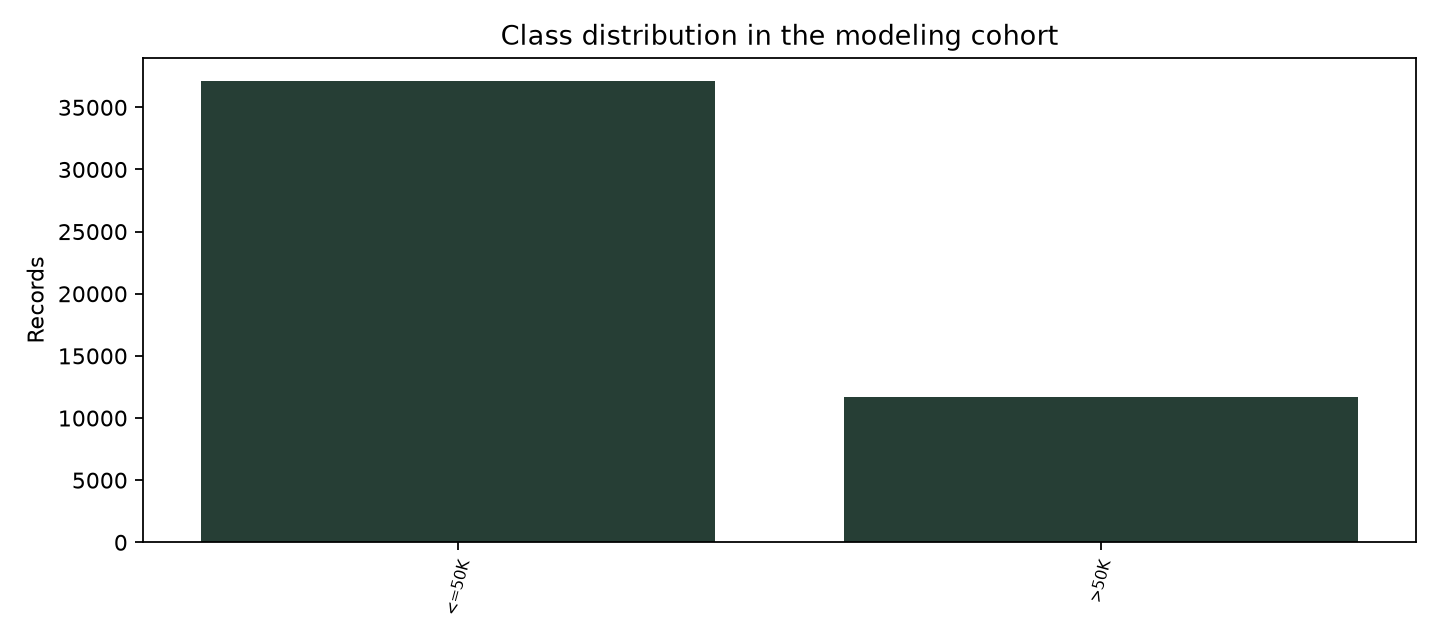

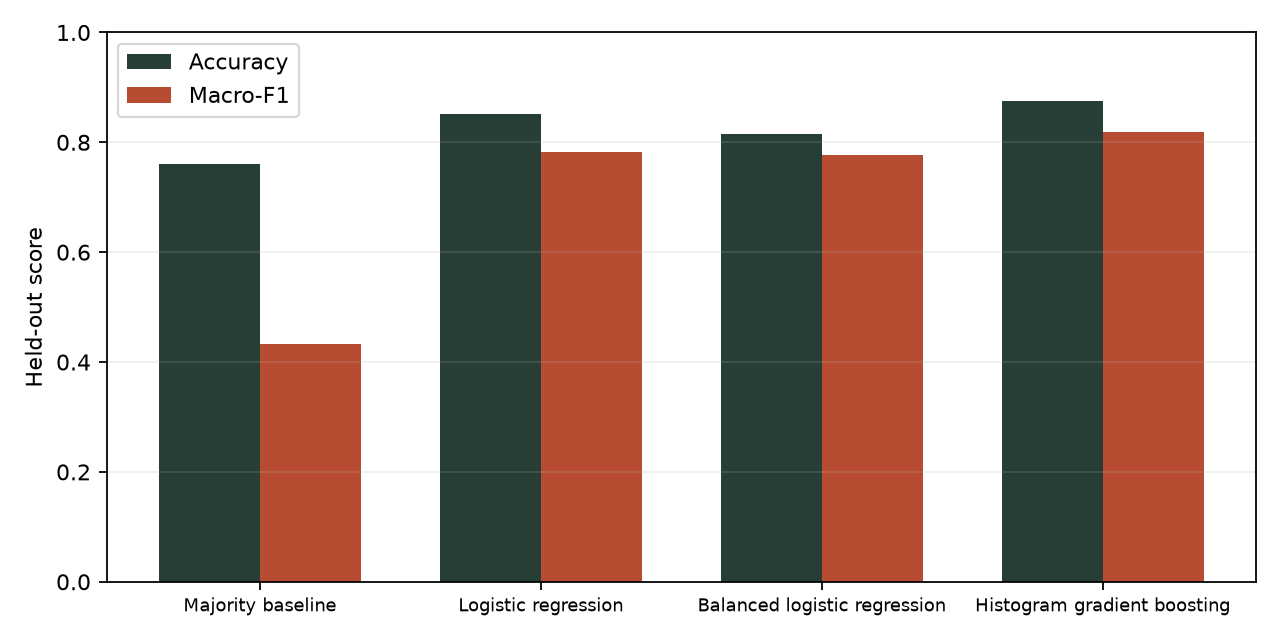

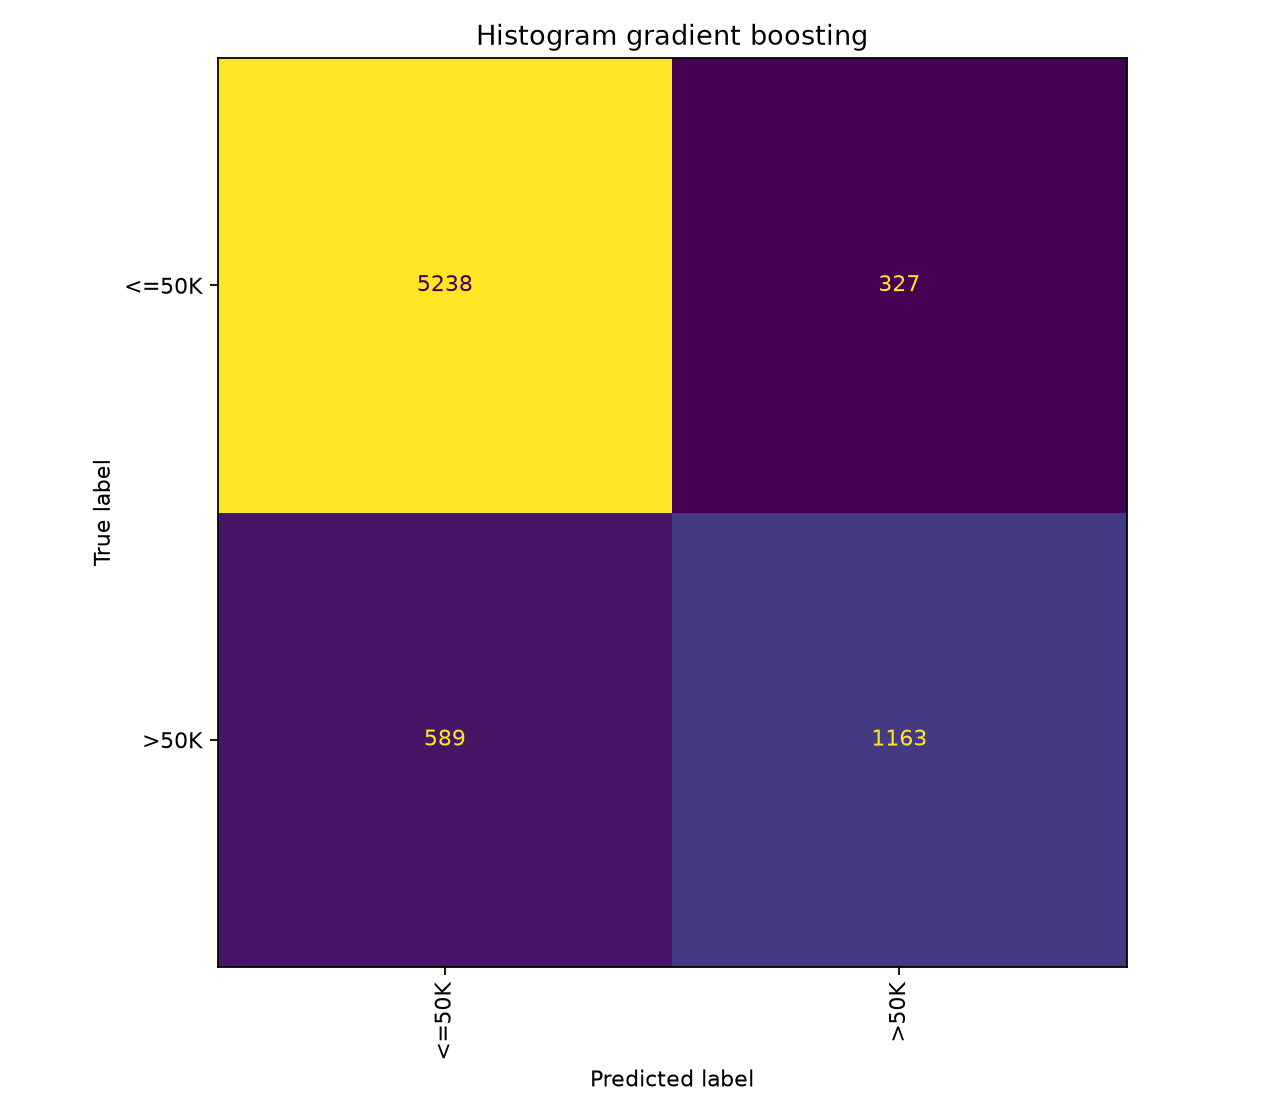

In [5]:
for figure in ['class_counts', 'scores', 'confusion']:
    display(Image(filename=f'reports/tabular/generated/{figure}.png', width=760))

## 5. Phân tích và giới hạn

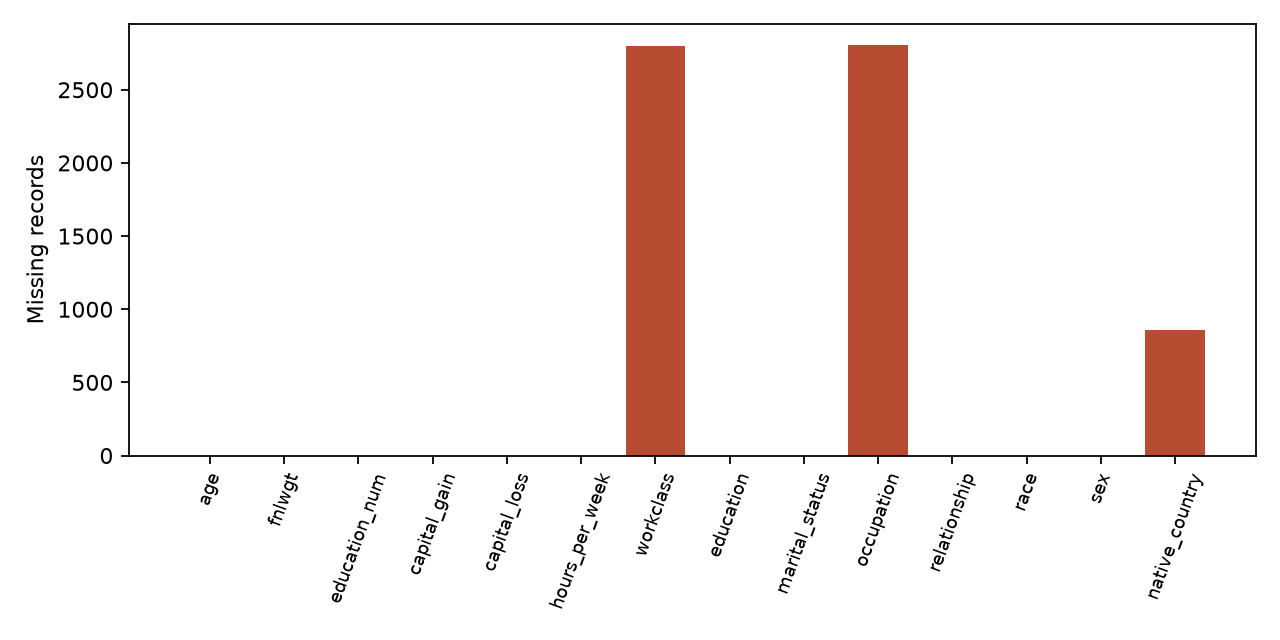

Majority baseline precision >50K: 0.0 recall >50K: 0.0
Logistic regression precision >50K: 0.7403 recall >50K: 0.5908
Balanced logistic regression precision >50K: 0.5764 recall >50K: 0.8459
Histogram gradient boosting precision >50K: 0.7805 recall >50K: 0.6638


In [6]:
display(Image(filename='reports/tabular/generated/missing.png', width=760))
for result in summary['models']:
    report = result['test']['per_class']['>50K']
    print(result['name'], 'precision >50K:', round(report['precision'],4), 'recall >50K:', round(report['recall'],4))

Dữ liệu lệch lớp, nên accuracy cần đọc cùng macro-F1 và recall của lớp >50K. Chỉ có một split và seed, không có khoảng tin cậy. Tập Census lịch sử không đại diện cho thu nhập hiện tại; split mới không so trực tiếp với điểm benchmark official. Thuộc tính fnlwgt được dùng như feature, không làm sample weight.

## 6. Kiểm tra kết quả

Audit kiểm tra checksum, split và tính lại accuracy, macro-F1, confusion từ predictions. Classifier được lưu ở `runs/`; bản báo cáo PDF và LaTeX nằm riêng theo track.

In [7]:
audit('tabular', check_models=True)

{'track': 'tabular', 'models': 4, 'test_rows': 7317, 'verified_artifacts': 8}

Báo cáo sử dụng AI được đính kèm tại `AI_USE_REPORT.md` trong repository.